In [7]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

In [8]:
# -------------------------------------------------
# Create Environment
# -------------------------------------------------

env = gym.make("FrozenLake-v1", is_slippery=False)

n_states = env.observation_space.n
n_actions = env.action_space.n

print("Number of States:", n_states)
print("Number of Actions:", n_actions)

Number of States: 16
Number of Actions: 4


In [9]:
# Hyperparameters

num_episodes = 10000
gamma = 0.99
alpha = 0.1

epsilon_start = 1.0
epsilon_min = 0.01
epsilon_decay = 0.9995

In [10]:
# -------------------------------------------------
# Initialize Q-table
# -------------------------------------------------

Q = np.zeros((n_states, n_actions))
episode_rewards = []


# -------------------------------------------------
# Epsilon-Greedy Action Selection
# -------------------------------------------------

def epsilon_greedy_action(state, epsilon):

    if np.random.random() < epsilon:
        return env.action_space.sample()

    else:
        return np.argmax(Q[state])

In [11]:
# -------------------------------------------------
# Generate One Complete Episode
# -------------------------------------------------

def generate_episode(epsilon):
    """
    Generates one episode using the current epsilon-greedy policy.
    Returns a list of (state, action, reward).
    """

    episode = []

    state, info = env.reset()

    for _ in range(max_steps_per_episode):
        action = epsilon_greedy_action(state, epsilon)

        next_state, reward, terminated, truncated, info = env.step(action)

        episode.append((state, action, reward))

        state = next_state

        if terminated or truncated:
            break

    return episode



In [15]:
# -------------------------------------------------
# Monte Carlo Control
# -------------------------------------------------

# Define the missing hyperparameter used in generate_episode
max_steps_per_episode = 100

epsilon = epsilon_start

for episode_num in range(num_episodes):

    # Generate a complete episode
    episode = generate_episode(epsilon)

    G = 0
    visited = set()

    # Calculate returns backwards
    for state, action, reward in reversed(episode):

        G = reward + gamma * G

        # First-visit Monte Carlo
        if (state, action) not in visited:

            visited.add((state, action))

            # Update Q-value
            Q[state, action] += alpha * (
                G - Q[state, action]
            )

    # Store episode reward
    total_reward = sum(
        step[2] for step in episode
    )

    episode_rewards.append(total_reward)

    # Decay epsilon
    epsilon = max(
        epsilon_min,
        epsilon * epsilon_decay
    )

print("Monte Carlo Control Training Completed!")
print("Final Epsilon:", epsilon)

Monte Carlo Control Training Completed!
Final Epsilon: 0.01


In [16]:
# -------------------------------------------------
# Extract Greedy Policy
# -------------------------------------------------

optimal_policy = np.argmax(Q, axis=1)
state_values = np.max(Q, axis=1)


In [17]:
# -------------------------------------------------
# Display Results
# -------------------------------------------------

def print_policy(policy):
    action_symbols = {
        0: "L",
        1: "D",
        2: "R",
        3: "U"
    }

    policy_grid = np.array(
        [action_symbols[action] for action in policy]
    ).reshape(4, 4)
    print("Name:          ")
    print("Register Number:      ")
    print("\nLearned Policy:")
    print(policy_grid)


def print_value_function(values):
    print("\nEstimated State-Value Function:")
    print(np.round(values.reshape(4, 4), 3))


print("\nFinal Q-table:")
print(np.round(Q, 3))

print_value_function(state_values)
print_policy(optimal_policy)

success_rate = np.mean(episode_rewards[-1000:])
print("\nAverage reward over last 1000 episodes:", success_rate)




Final Q-table:
[[0.724 0.951 0.75  0.671]
 [0.766 0.    0.549 0.498]
 [0.671 0.685 0.668 0.741]
 [0.717 0.    0.285 0.534]
 [0.705 0.961 0.    0.678]
 [0.    0.    0.    0.   ]
 [0.    0.945 0.    0.742]
 [0.    0.    0.    0.   ]
 [0.823 0.    0.97  0.757]
 [0.806 0.941 0.98  0.   ]
 [0.949 0.99  0.    0.954]
 [0.    0.    0.    0.   ]
 [0.    0.    0.    0.   ]
 [0.    0.853 0.987 0.881]
 [0.933 0.99  1.    0.968]
 [0.    0.    0.    0.   ]]

Estimated State-Value Function:
[[0.951 0.766 0.741 0.717]
 [0.961 0.    0.945 0.   ]
 [0.97  0.98  0.99  0.   ]
 [0.    0.987 1.    0.   ]]
Name:          
Register Number:      

Learned Policy:
[['D' 'L' 'U' 'L']
 ['D' 'L' 'D' 'L']
 ['R' 'R' 'D' 'L']
 ['L' 'R' 'R' 'L']]

Average reward over last 1000 episodes: 0.985


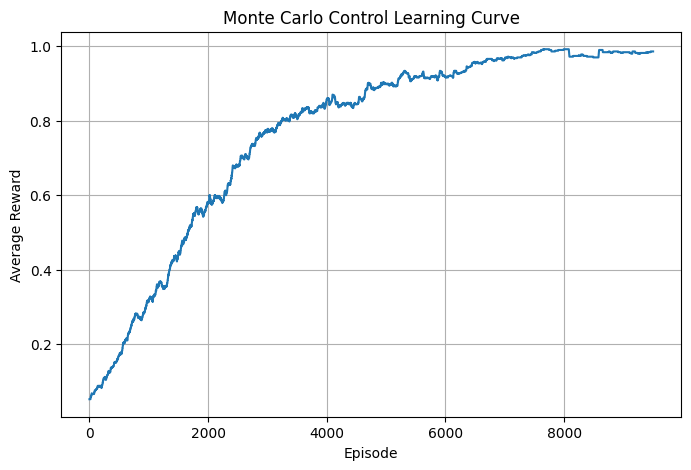

In [18]:
# -------------------------------------------------
# Plot Learning Curve
# -------------------------------------------------

window = 500
moving_average = np.convolve(
    episode_rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(8, 5))
plt.plot(moving_average)
plt.xlabel("Episode")
plt.ylabel("Average Reward")
plt.title("Monte Carlo Control Learning Curve")
plt.grid(True)
plt.show()

env.close()